# DIGITZ East Legon Exploratory Analysis

This notebook presents an exploratory analysis of 222 East Legon property listings. It forms part of DIGITZ’s earlier research across multiple Accra residential ecosystems, developed alongside two years of experience in property operations. The work involved reviewing published price benchmarks, manually collecting listings, verifying individual records and analysing the selected sample in Python.

## Data source and sample selection

The sale and rental listings were manually collected from Meqasa over a one-week period in early April 2026. Selection was purposive, with published ecosystem price benchmarks guiding the price range covered. Repeat advertisements identified as referring to the same property were excluded. Because selection was guided by price, the observed price distribution and summary statistics reflect the selected sample and should not be interpreted as estimates for the entire East Legon residential market.

## 1. Dataset import and sample size

The sample contains 99 sale listings and 123 rental listings. Sales and rentals are analysed separately because purchase asking prices and monthly rental asking prices measure different things.

In [1]:
import pandas as pd

file_path = "DIGITZ_East_Legon_Exploratory_Data.xlsx"

sales = pd.read_excel(file_path, sheet_name="🏡 Sales Hub")
rentals = pd.read_excel(file_path, sheet_name="🔑 Rentals Lounge")

print("Sales listings:", len(sales))
print("Rental listings:", len(rentals))
print("Total listings:", len(sales) + len(rentals))

Sales listings: 99
Rental listings: 123
Total listings: 222


In [2]:
print("Sales columns:")
print(sales.columns.tolist())

print("\nRental columns:")
print(rentals.columns.tolist())

Sales columns:
['Deal', 'Title', 'Price (GH₵)', 'Price (USD)', 'Price per BR (USD)', 'Property Type', 'Bedrooms', 'Location', 'Listing ID', 'Source URL', 'FX_Rate']

Rental columns:
['Deal', 'Title', 'Price (GH₵)', 'Price (USD)', 'Price per BR (USD)', 'Property Type', 'Bedrooms', 'Location', 'Listing ID', 'Source URL', 'FX_Rate']


In [3]:
selected_columns = [
    "Deal",
    "Title",
    "Price (GH₵)",
    "Property Type",
    "Bedrooms",
    "Location"
]

sales[selected_columns].head()

,Deal,Title,Price (GH₵),Property Type,Bedrooms,Location
0,Sale,1 bedroom apartment for sale at East Legon ANC,973587,Apartment,1,East Legon
1,Sale,1 bedroom apartment for sale at East Legon,1030856,Apartment,1,East Legon
2,Sale,1 bedroom apartment for sale at East Legon,1293270,Apartment,1,East Legon
3,Sale,1 bedroom furnished apartment for sale at East...,1349500,Apartment,1,East Legon
4,Sale,1 bedroom furnished apartment for sale at East...,1374475,Apartment,1,East Legon


In [4]:
rentals[selected_columns].head()

,Deal,Title,Price (GH₵),Property Type,Bedrooms,Location
0,Rent,1 bedroom apartment for rent at East Legon,4000,Apartment,1,East Legon
1,Rent,1 bedroom apartment for rent at East Legon,4000,Apartment,1,East Legon
2,Rent,1 bedroom apartment for rent at East Legon,5000,Apartment,1,East Legon
3,Rent,1 bedroom furnished apartment for rent at East...,5623,Apartment,1,East Legon
4,Rent,1 bedroom furnished apartment for rent at East...,6000,Apartment,1,East Legon


In [5]:
print("Sales dataset shape:", sales.shape)
print("Rentals dataset shape:", rentals.shape)

Sales dataset shape: (99, 11)
Rentals dataset shape: (123, 11)


In [6]:
missing_values = pd.DataFrame({
    "Sales missing": sales.isna().sum(),
    "Rentals missing": rentals.isna().sum()
})

missing_values

,Sales missing,Rentals missing
Deal,0,0
Title,0,0
Price (GH₵),0,0
Price (USD),0,0
Price per BR (USD),0,0
Property Type,0,0
Bedrooms,0,0
Location,0,0
Listing ID,0,0
Source URL,0,0


In [7]:
print("Sales deal values:", sales["Deal"].unique())
print("Rental deal values:", rentals["Deal"].unique())

print("Sales locations:", sales["Location"].unique())
print("Rental locations:", rentals["Location"].unique())

print("Sales property types:", sales["Property Type"].unique())
print("Rental property types:", rentals["Property Type"].unique())

Sales deal values: ['Sale']
Rental deal values: ['Rent']
Sales locations: ['East Legon']
Rental locations: ['East Legon']
Sales property types: ['Apartment' 'House' 'Townhouse']
Rental property types: ['Apartment' 'House' 'Townhouse']


In [8]:
duplicate_checks = pd.DataFrame({
    "Sales": [
        sales["Listing ID"].duplicated().sum(),
        sales["Source URL"].duplicated().sum(),
        sales.duplicated().sum()
    ],
    "Rentals": [
        rentals["Listing ID"].duplicated().sum(),
        rentals["Source URL"].duplicated().sum(),
        rentals.duplicated().sum()
    ]
}, index=[
    "Duplicate listing IDs",
    "Duplicate source URLs",
    "Exact duplicate rows"
])

duplicate_checks

,Sales,Rentals
Duplicate listing IDs,0,0
Duplicate source URLs,0,0
Exact duplicate rows,0,0


### Initial data-quality checks

The sales and rental datasets contain 11 variables each, with no missing values in the recorded fields. Tenure, location and property-type labels are internally consistent. The datasets distinguish apartments, houses and townhouses as separate property categories.

Each listing underwent manual verification during the initial collection stage, including duplicate review. Listings with matching titles and asking prices were retained where manually confirmed to represent distinct properties. As an additional reproducibility check, this notebook detected no duplicated listing IDs, source URLs or exact rows.

These checks establish structural completeness, categorical consistency and record-level uniqueness within the supplied dataset. They do not independently reverify the accuracy or current availability of every listing.

## 2. Property-type composition

This section examines how apartments, houses and townhouses are distributed within the sales and rental samples. Counts and percentages are calculated separately because the two tenure datasets have different sample sizes.

In [9]:
sales_property_counts = sales["Property Type"].value_counts()
rental_property_counts = rentals["Property Type"].value_counts()

print("Sales property counts:")
print(sales_property_counts)

print("\nRental property counts:")
print(rental_property_counts)

Sales property counts:
Property Type
House        46
Apartment    40
Townhouse    13
Name: count, dtype: int64

Rental property counts:
Property Type
Apartment    65
House        41
Townhouse    17
Name: count, dtype: int64


In [10]:
sales_property_percentages = (
    sales_property_counts / len(sales) * 100
).round(1)

rental_property_percentages = (
    rental_property_counts / len(rentals) * 100
).round(1)

print("Sales property percentages:")
print(sales_property_percentages)

print("\nRental property percentages:")
print(rental_property_percentages)

Sales property percentages:
Property Type
House        46.5
Apartment    40.4
Townhouse    13.1
Name: count, dtype: float64

Rental property percentages:
Property Type
Apartment    52.8
House        33.3
Townhouse    13.8
Name: count, dtype: float64


### Property-type result

Houses constitute the largest share of the sales sample at 46.5%, followed by apartments at 40.4% and townhouses at 13.1%. Apartments constitute the largest share of the rental sample at 52.8%, followed by houses at 33.3% and townhouses at 13.8%.

The observed composition indicates a house-led sales sample and an apartment-led rental sample. These results describe advertised inventory within the selected sample and do not directly measure completed transactions, occupancy or demand.

## 3. Bedroom composition

This section examines how listings are distributed across bedroom sizes. Sales and rentals are analysed separately to identify the most frequently observed bedroom category within each sample.

In [11]:
sales_bedroom_counts = sales["Bedrooms"].value_counts().sort_index()
rental_bedroom_counts = rentals["Bedrooms"].value_counts().sort_index()

bedroom_composition = pd.DataFrame({
    "Sales count": sales_bedroom_counts,
    "Rental count": rental_bedroom_counts
})

bedroom_composition

,Sales count,Rental count
Bedrooms,,
1,15,26
2,21,31
3,37,39
4,16,17
5,10,10


In [12]:
bedroom_composition["Sales percentage"] = (
    bedroom_composition["Sales count"] / len(sales) * 100
).round(1)

bedroom_composition["Rental percentage"] = (
    bedroom_composition["Rental count"] / len(rentals) * 100
).round(1)

bedroom_composition = bedroom_composition[
    [
        "Sales count",
        "Sales percentage",
        "Rental count",
        "Rental percentage"
    ]
]

bedroom_composition

,Sales count,Sales percentage,Rental count,Rental percentage
Bedrooms,,,,
1,15,15.2,26,21.1
2,21,21.2,31,25.2
3,37,37.4,39,31.7
4,16,16.2,17,13.8
5,10,10.1,10,8.1


### Bedroom-composition result

Three-bedroom properties constitute the modal category in both tenure samples, accounting for 37.4% of sale listings and 31.7% of rental listings.

Within the sales sample, one- and two-bedroom listings collectively represent 36.4%, while three- to five-bedroom listings represent 63.6%. Within the rental sample, the corresponding shares are 46.3% and 53.7%.

The sample therefore contains a greater proportional concentration of smaller units among rental listings and larger units among sale listings. This describes the composition of advertised inventory and does not, by itself, identify the occupants or explain the underlying demand.

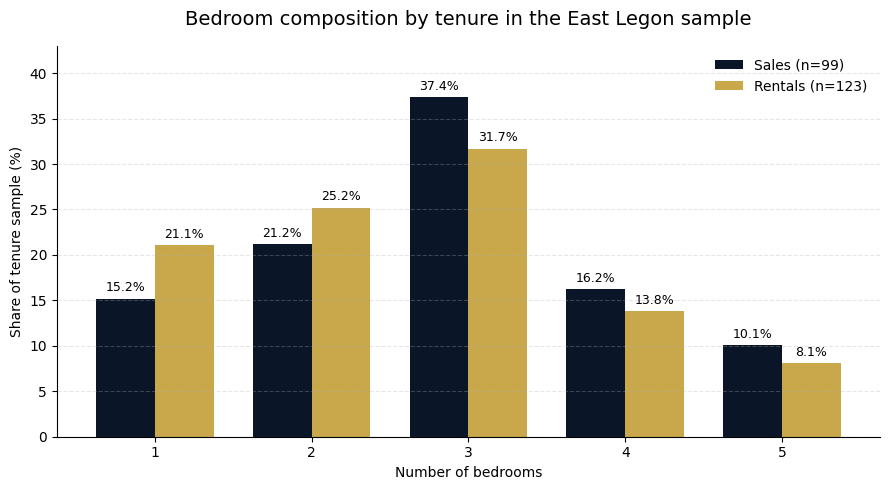

In [13]:
import matplotlib.pyplot as plt

bedroom_percentages = bedroom_composition[
    ["Sales percentage", "Rental percentage"]
]

ax = bedroom_percentages.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#0A1628", "#C9A84C"],
    width=0.75
)

ax.set_title(
    "Bedroom composition by tenure in the East Legon sample",
    fontsize=14,
    pad=15
)
ax.set_xlabel("Number of bedrooms")
ax.set_ylabel("Share of tenure sample (%)")
ax.legend(["Sales (n=99)", "Rentals (n=123)"], frameon=False)
ax.set_xticklabels(bedroom_percentages.index, rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

ax.set_ylim(0, 43)

plt.tight_layout()
plt.show()

## 4. Pricing architecture

Sales asking prices and monthly rental asking prices are analysed separately. Before calculating summary statistics, the price fields are checked to confirm that Python recognises them as numeric values and that all recorded prices are positive.

In [14]:
print("Sales price data type:", sales["Price (GH₵)"].dtype)
print("Rental price data type:", rentals["Price (GH₵)"].dtype)

print(
    "Non-positive sales prices:",
    (sales["Price (GH₵)"] <= 0).sum()
)

print(
    "Non-positive rental prices:",
    (rentals["Price (GH₵)"] <= 0).sum()
)

Sales price data type: int64
Rental price data type: int64
Non-positive sales prices: 0
Non-positive rental prices: 0


### Currency normalisation

Asking prices are expressed in USD by applying a fixed analytical rate of GH₵11.43 per USD 1 to the workbook's cedi price field. This is a project convention, not a live exchange rate. Rental asking prices are treated as monthly amounts; this notebook does not convert rental periods.

The notebook's `Calculated Price (USD)` and `Calculated Price (USD/month)` columns govern all price statistics and charts. The workbook's stored `Price (USD)` values, based on GH₵11.4293 per USD 1, are retained for reconciliation only. The final checks confirm agreement within the difference implied by the two rates, allowing USD 0.01 for rounding.


In [15]:
FX_RATE = 11.43

sales_analysis = sales.copy()
rentals_analysis = rentals.copy()

sales_analysis["Calculated Price (USD)"] = (
    sales_analysis["Price (GH₵)"] / FX_RATE
)

rentals_analysis["Calculated Price (USD/month)"] = (
    rentals_analysis["Price (GH₵)"] / FX_RATE
)

sales_analysis[
    ["Price (GH₵)", "Calculated Price (USD)"]
].head()

,Price (GH₵),Calculated Price (USD)
0,973587,85178.215223
1,1030856,90188.626422
2,1293270,113146.981627
3,1349500,118066.491689
4,1374475,120251.531059


In [16]:
sales_stats = sales_analysis[
    "Calculated Price (USD)"
].describe(percentiles=[0.25, 0.50, 0.75])

rental_stats = rentals_analysis[
    "Calculated Price (USD/month)"
].describe(percentiles=[0.25, 0.50, 0.75])

price_summary = pd.DataFrame({
    "Sales asking price (USD)": sales_stats,
    "Monthly asking rent (USD)": rental_stats
})

price_summary.loc["IQR"] = (
    price_summary.loc["75%"] - price_summary.loc["25%"]
)

price_summary.loc["Range"] = (
    price_summary.loc["max"] - price_summary.loc["min"]
)

price_summary = price_summary.rename(index={
    "count": "Count",
    "mean": "Mean",
    "std": "Standard deviation",
    "min": "Minimum",
    "25%": "25th percentile (Q1)",
    "50%": "Median",
    "75%": "75th percentile (Q3)",
    "max": "Maximum"
})

price_summary.round(0)

,Sales asking price (USD),Monthly asking rent (USD)
Count,99.0,123.0
Mean,383676.0,2372.0
Standard deviation,309395.0,1537.0
Minimum,85178.0,350.0
25th percentile (Q1),185498.0,1181.0
Median,281715.0,2100.0
75th percentile (Q3),453850.0,3244.0
Maximum,1603354.0,8399.0
IQR,268352.0,2063.0
Range,1518176.0,8049.0


### Overall pricing result

Using the fixed analytical rate of GH₵11.43 per USD 1, the median sale asking price is approximately USD 281,715, while the mean is approximately USD 383,676. The middle 50% of sale asking prices lies between USD 185,498 and USD 453,850, producing an interquartile range of USD 268,352.

The median monthly asking rent is approximately USD 2,100, while the mean is approximately USD 2,372. The middle 50% of monthly asking rents lies between USD 1,181 and USD 3,244, producing an interquartile range of USD 2,063.

In both tenure samples, the mean exceeds the median. This is consistent with higher-priced listings pulling the arithmetic average upward. The median and interquartile range therefore provide more resistant summaries of the typical price position and central spread.

All figures describe normalised asking prices within the selected sample. They do not represent completed transaction prices.

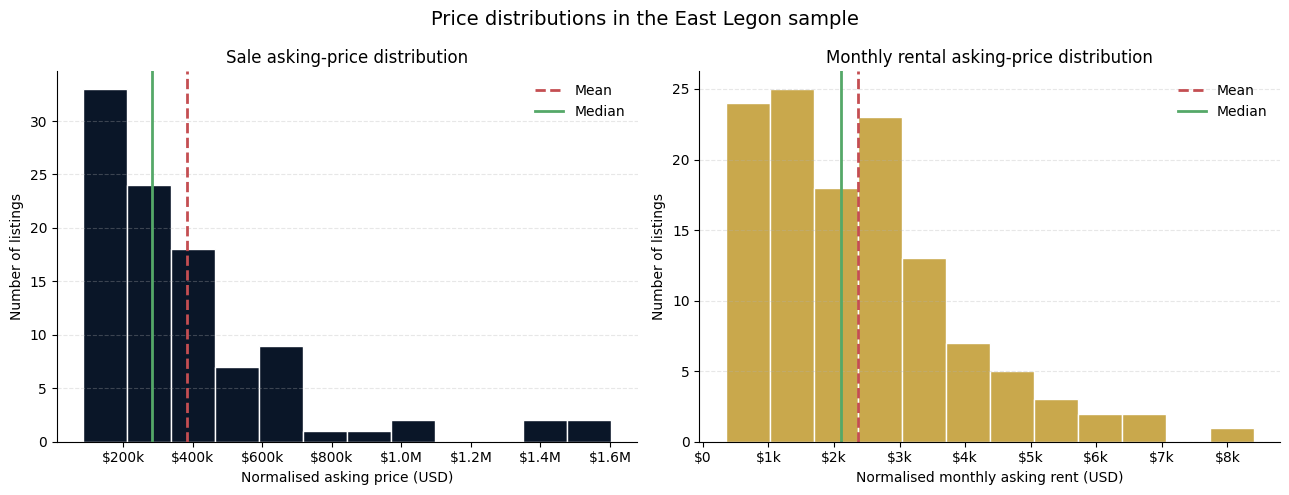

In [17]:
from matplotlib.ticker import FuncFormatter


# Format chart values as readable USD labels
def format_usd(value, position):
    if value >= 1_000_000:
        return f"${value / 1_000_000:.1f}M"
    if value >= 1_000:
        return f"${value / 1_000:.0f}k"
    return f"${value:.0f}"


# Select the calculated price columns
sales_prices = sales_analysis["Calculated Price (USD)"]
rental_prices = rentals_analysis["Calculated Price (USD/month)"]


# Create two charts beside each other
fig, axes = plt.subplots(1, 2, figsize=(13, 5))


# Sales asking-price histogram
axes[0].hist(
    sales_prices,
    bins=12,
    color="#0A1628",
    edgecolor="white"
)

axes[0].axvline(
    sales_prices.mean(),
    color="#C44E52",
    linestyle="--",
    linewidth=2,
    label="Mean"
)

axes[0].axvline(
    sales_prices.median(),
    color="#55A868",
    linestyle="-",
    linewidth=2,
    label="Median"
)

axes[0].set_title("Sale asking-price distribution")
axes[0].set_xlabel("Normalised asking price (USD)")
axes[0].set_ylabel("Number of listings")
axes[0].legend(frameon=False)
axes[0].xaxis.set_major_formatter(
    FuncFormatter(format_usd)
)


# Monthly rental asking-price histogram
axes[1].hist(
    rental_prices,
    bins=12,
    color="#C9A84C",
    edgecolor="white"
)

axes[1].axvline(
    rental_prices.mean(),
    color="#C44E52",
    linestyle="--",
    linewidth=2,
    label="Mean"
)

axes[1].axvline(
    rental_prices.median(),
    color="#55A868",
    linestyle="-",
    linewidth=2,
    label="Median"
)

axes[1].set_title(
    "Monthly rental asking-price distribution"
)
axes[1].set_xlabel(
    "Normalised monthly asking rent (USD)"
)
axes[1].set_ylabel("Number of listings")
axes[1].legend(frameon=False)
axes[1].xaxis.set_major_formatter(
    FuncFormatter(format_usd)
)


# Apply the same styling to both charts
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )


# Overall figure title
fig.suptitle(
    "Price distributions in the East Legon sample",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [18]:
sales_skewness = sales_prices.skew()
rental_skewness = rental_prices.skew()

print(
    "Sales price skewness:",
    round(sales_skewness, 2)
)

print(
    "Rental price skewness:",
    round(rental_skewness, 2)
)

Sales price skewness: 2.17
Rental price skewness: 1.19


### Price-distribution shape

Both price distributions are positively skewed. The sales asking-price distribution has a skewness value of 2.17, while the monthly rental asking-price distribution has a skewness value of 1.19.

The sales distribution exhibits the stronger right-hand tail, reflecting a small number of substantially higher-priced listings. This is consistent with the sales mean of USD 383,676 exceeding the median of USD 281,715.

The rental distribution is also right-skewed, although less strongly. Its mean monthly asking rent of USD 2,372 exceeds its median of USD 2,100.

The histogram, skewness values and mean–median differences provide converging descriptive evidence that the median is more representative of the central price position than the mean for both samples.

### Asking prices by bedroom category

Overall price statistics can conceal differences between property sizes. This subsection groups listings by bedroom count and calculates the sample size, median, first quartile, third quartile and interquartile range within each category.

The DIGITZ minimum-sample rule requires at least eight listings within a category before reporting its median and quartile statistics.

In [19]:
sales_by_bedroom = (
    sales_analysis
    .groupby("Bedrooms")["Calculated Price (USD)"]
    .agg(
        Count="count",
        Median="median",
        Q1=lambda values: values.quantile(0.25),
        Q3=lambda values: values.quantile(0.75)
    )
)

sales_by_bedroom["IQR"] = (
    sales_by_bedroom["Q3"] - sales_by_bedroom["Q1"]
)

sales_by_bedroom.round(0)

,Count,Median,Q1,Q3,IQR
Bedrooms,,,,,
1,15,127905.0,119159.0,158809.0,39650.0
2,21,200419.0,139983.0,281715.0,141732.0
3,37,295166.0,237927.0,442749.0,204823.0
4,16,466881.0,386719.0,665107.0,278388.0
5,10,1007172.0,826729.0,1457607.0,630877.0


In [20]:
rentals_by_bedroom = (
    rentals_analysis
    .groupby("Bedrooms")[
        "Calculated Price (USD/month)"
    ]
    .agg(
        Count="count",
        Median="median",
        Q1=lambda values: values.quantile(0.25),
        Q3=lambda values: values.quantile(0.75)
    )
)

rentals_by_bedroom["IQR"] = (
    rentals_by_bedroom["Q3"] -
    rentals_by_bedroom["Q1"]
)

rentals_by_bedroom.round(0)

,Count,Median,Q1,Q3,IQR
Bedrooms,,,,,
1,26,968.0,755.0,1181.0,426.0
2,31,1574.0,1084.0,2165.0,1081.0
3,39,2537.0,1854.0,3144.0,1290.0
4,17,3739.0,3050.0,4409.0,1359.0
5,10,5726.0,5136.0,6388.0,1253.0


### Asking-price progression by bedroom category

Median asking prices increase consistently with bedroom count in both tenure samples.

For sales, the median rises from USD 127,905 for one-bedroom listings to USD 1,007,172 for five-bedroom listings. The increase is especially pronounced between the four- and five-bedroom categories. The five-bedroom category also has the widest interquartile range, indicating substantial price dispersion within that category.

For rentals, the median monthly asking rent rises from USD 968 for one-bedroom listings to USD 5,726 for five-bedroom listings. The progression is more gradual than in the sales sample, although price dispersion remains substantial within the larger-bedroom categories.

All bedroom categories satisfy the DIGITZ minimum reporting threshold of eight listings. These comparisons do not control for property type, floor area, condition, furnishing, amenities or precise sub-location.

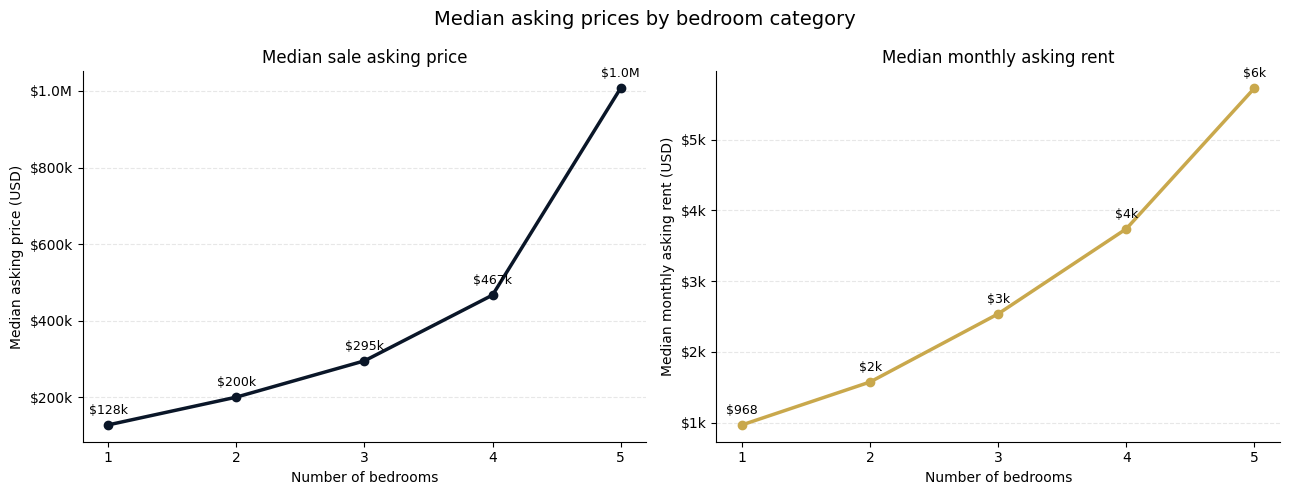

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))


# Median sale asking price by bedroom count
axes[0].plot(
    sales_by_bedroom.index,
    sales_by_bedroom["Median"],
    marker="o",
    linewidth=2.5,
    color="#0A1628"
)

axes[0].set_title("Median sale asking price")
axes[0].set_xlabel("Number of bedrooms")
axes[0].set_ylabel("Median asking price (USD)")
axes[0].set_xticks(sales_by_bedroom.index)
axes[0].yaxis.set_major_formatter(
    FuncFormatter(format_usd)
)


# Median monthly asking rent by bedroom count
axes[1].plot(
    rentals_by_bedroom.index,
    rentals_by_bedroom["Median"],
    marker="o",
    linewidth=2.5,
    color="#C9A84C"
)

axes[1].set_title("Median monthly asking rent")
axes[1].set_xlabel("Number of bedrooms")
axes[1].set_ylabel("Median monthly asking rent (USD)")
axes[1].set_xticks(rentals_by_bedroom.index)
axes[1].yaxis.set_major_formatter(
    FuncFormatter(format_usd)
)


# Add exact values beside the points
for bedrooms, value in sales_by_bedroom["Median"].items():
    axes[0].annotate(
        format_usd(value, None),
        (bedrooms, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

for bedrooms, value in rentals_by_bedroom["Median"].items():
    axes[1].annotate(
        format_usd(value, None),
        (bedrooms, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )


for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.3)


fig.suptitle(
    "Median asking prices by bedroom category",
    fontsize=14
)

plt.tight_layout()
plt.show()

## 5. Property type × bedroom × tenure

Bedroom count and property type are examined together to show how the sample is structurally distributed. This prevents bedroom-level patterns from being interpreted without considering the type of housing represented within each category.

In [22]:
listing_structure = pd.concat(
    [
        sales[
            ["Deal", "Property Type", "Bedrooms"]
        ],
        rentals[
            ["Deal", "Property Type", "Bedrooms"]
        ]
    ],
    ignore_index=True
)

property_bedroom_tenure = pd.crosstab(
    index=[
        listing_structure["Deal"],
        listing_structure["Property Type"]
    ],
    columns=listing_structure["Bedrooms"],
    margins=True,
    margins_name="Total"
)

property_bedroom_tenure

Bedrooms              1   2   3   4   5  Total
Deal  Property Type                           
Rent  Apartment      26  22  16   1   0     65
      House           0   9  13   9  10     41
      Townhouse       0   0  10   7   0     17
Sale  Apartment      15  15  10   0   0     40
      House           0   4  19  13  10     46
      Townhouse       0   2   8   3   0     13
Total                41  52  76  33  20    222

### Property type × bedroom × tenure result

The cross-tabulation shows a clear relationship between property type and bedroom count within the selected sample.

Apartments are concentrated in the smaller-bedroom categories. Rental apartments comprise 26 one-bedroom, 22 two-bedroom and 16 three-bedroom listings, with only one four-bedroom listing and no five-bedroom listings. Sale apartments comprise 15 one-bedroom, 15 two-bedroom and 10 three-bedroom listings.

Houses occupy the larger-bedroom categories. All 20 five-bedroom listings in the combined sample are houses, evenly divided between 10 sales and 10 rentals.

Townhouses are concentrated in the three- and four-bedroom categories, with a limited two-bedroom presence among sales. No one-bedroom or five-bedroom townhouses are recorded.

These zero counts describe the selected sample and should not be interpreted as proof that such property combinations do not exist anywhere in East Legon.

## 6. Rental-to-sale listing ratios

The rental-to-sale listing ratio compares the number of rental advertisements with the number of sale advertisements within the same property-type and bedroom category.

A ratio above 1 indicates more rental listings than sale listings in the selected sample. A ratio below 1 indicates fewer rental listings than sale listings. The measure describes relative advertised inventory and does not directly measure transactions or demand.

In [23]:
property_order = [
    "Apartment",
    "House",
    "Townhouse"
]

bedroom_order = [1, 2, 3, 4, 5]


sales_structure = pd.crosstab(
    sales["Property Type"],
    sales["Bedrooms"]
).reindex(
    index=property_order,
    columns=bedroom_order,
    fill_value=0
)


rental_structure = pd.crosstab(
    rentals["Property Type"],
    rentals["Bedrooms"]
).reindex(
    index=property_order,
    columns=bedroom_order,
    fill_value=0
)


rental_to_sale_ratio = (
    rental_structure /
    sales_structure.where(sales_structure != 0)
).round(2)

In [24]:
sufficient_sample = (
    (sales_structure >= 8) &
    (rental_structure >= 8)
)

reportable_ratio = rental_to_sale_ratio.where(
    sufficient_sample
)

reportable_ratio

Bedrooms,1,2,3,4,5
Property Type,,,,,
Apartment,1.73,1.47,1.60,NaN,NaN
House,NaN,NaN,0.68,0.69,1.0
Townhouse,NaN,NaN,1.25,NaN,NaN


### Rental-to-sale ratio result

Among categories meeting the minimum threshold of eight listings in both tenure samples, one-, two- and three-bedroom apartments have rental-to-sale listing ratios of 1.73, 1.47 and 1.60, respectively. Rental advertisements therefore outnumber sale advertisements across all three reportable apartment categories.

Three- and four-bedroom houses have ratios of 0.68 and 0.69, indicating fewer rental advertisements than sale advertisements within the selected sample. Five-bedroom houses have a balanced ratio of 1.00.

Three-bedroom townhouses have a ratio of 1.25, indicating a modest rental-listing skew.

Ratios for categories failing the minimum sample threshold are not interpreted. These results describe the relative composition of advertised inventory and do not directly measure demand, transaction activity or occupancy.

## 7. Composition summary

The purposively selected East Legon sample contains 222 property advertisements, comprising 99 sale listings and 123 rental listings. Houses form the largest property-type share of the sales sample, while apartments form the largest share of the rental sample. Townhouses represent the smallest property-type category in both tenure samples.

Three-bedroom properties constitute the modal bedroom category for both sales and rentals. Rental listings show a greater proportional concentration of one- and two-bedroom units, while sale listings show a greater concentration of three- to five-bedroom units.

Median asking prices increase with bedroom count in both tenure samples. The overall sales and rental price distributions are positively skewed, meaning that a limited number of higher-priced listings raise the mean above the median.

The property-type and bedroom cross-tabulation shows that apartments are concentrated in smaller-bedroom categories, houses occupy the larger-bedroom categories, and townhouses are concentrated mainly among three- and four-bedroom listings.

Among reportable categories, apartment listings are rental-skewed across the one-, two- and three-bedroom categories. Three- and four-bedroom houses are sale-skewed, while five-bedroom houses are evenly represented between sales and rentals.

These findings describe the structure and asking-price characteristics of the selected dataset. They do not establish demand, occupancy, market-wide prevalence or completed transaction behaviour.

## Reproducibility note

This notebook uses `DIGITZ_East_Legon_Exploratory_Data.xlsx`, with the worksheets `🏡 Sales Hub` and `🔑 Rentals Lounge`. Place the workbook in the notebook's working directory and retain these exact names. Saved outputs include the analysis tables and charts.

The software versions used for the saved run are printed in the environment cell below. The final reconciliation checks confirm the principal sample totals, category counts, percentages and currency calculations.

Results should be interpreted within the collection and selection scope described above.


In [25]:
import sys
import matplotlib
import openpyxl

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("openpyxl:", openpyxl.__version__)

Python: 3.13.15
pandas: 2.2.3
matplotlib: 3.10.0
openpyxl: 3.1.5


In [26]:
# Final reconciliation checks

assert len(sales) == 99
assert len(rentals) == 123
assert len(sales) + len(rentals) == 222

assert sales_property_counts.sum() == len(sales)
assert rental_property_counts.sum() == len(rentals)

assert sales_bedroom_counts.sum() == len(sales)
assert rental_bedroom_counts.sum() == len(rentals)

assert property_bedroom_tenure.iloc[-1, -1] == 222

# Reconcile unrounded percentages; displayed values can sum to 99.9%.
from math import isclose
assert isclose((sales_property_counts / len(sales) * 100).sum(), 100.0, abs_tol=1e-9)
assert isclose((rental_property_counts / len(rentals) * 100).sum(), 100.0, abs_tol=1e-9)

# Difference relative to stored USD implied by the two documented FX rates.
WORKBOOK_FX_RATE = 11.4293
fx_relative_tolerance = abs(WORKBOOK_FX_RATE / FX_RATE - 1)
usd_rounding_tolerance = 0.01

for dataset, calculated_column in [
    (sales_analysis, "Calculated Price (USD)"),
    (rentals_analysis, "Calculated Price (USD/month)"),
]:
    stored = dataset["Price (USD)"]
    calculated = dataset[calculated_column]
    assert stored.notna().all() and (stored > 0).all()
    assert calculated.notna().all() and (calculated > 0).all()
    # Confirm the documented basis of the stored values as well.
    assert ((stored - dataset["Price (GH₵)"] / WORKBOOK_FX_RATE).abs() <= usd_rounding_tolerance).all()
    allowed_difference = stored.abs() * fx_relative_tolerance + usd_rounding_tolerance
    assert ((calculated - stored).abs() <= allowed_difference).all(), "FX reconciliation failed"

print("All final reconciliation checks passed.")

All final reconciliation checks passed.
